In [1]:
import pandas as pd
import numpy as np

# Here, in this session, we will learn some important methods of Pandas Dataframe. The list of methods are given below

1. value_counts()
2. sort_values()
3. rank()
4. sort index()
5. set index()
6. rename index() and rename()
7. reset index()
8. unique & nunique()
9. isnull/notnull/hasnans()
10. dropna()
11. fillna()
12. drop_duplicates
13. drop()
14. apply()
15. isin()
16. corr()
17. nlargest() and nsmallest
18. insert()
19. copy()

# Let's start.

In [2]:
# 1) value_counts(): Series and dataframe
# IN Dataframe, it returns the no_of times each row repeated
# In Series, it returns the no_of_times each value repeated

marks = pd.DataFrame([
    [100,80,10],
    [90,70,7],
    [120,100,14],
    [80,70,14],
    [80,70,14]
],columns=['iq','marks','package'])

marks

,iq,marks,package
0,100,80,10
1,90,70,7
2,120,100,14
3,80,70,14
4,80,70,14


In [3]:
marks.value_counts()

# Row 80 70 14 repeated 2 times.
# Row 90, 70, 7 repeated 1 time and so onn

iq   marks  package
80   70     14         2
90   70     7          1
100  80     10         1
120  100    14         1
Name: count, dtype: int64

In [4]:
# Series

pd.Series([1, 2, 2, 3, 3, 3, 4, 4, 4, 4]).value_counts()

4    4
3    3
2    2
1    1
Name: count, dtype: int64

In [5]:
# Examples of vaue_counts()

ipl_matches = pd.read_csv(r'00 ipl_matches.csv')

In [6]:
ipl_matches.head()

,ID,City,Date,Season,MatchNumber,Team1,Team2,Venue,TossWinner,TossDecision,SuperOver,WinningTeam,WonBy,Margin,method,Player_of_Match,Team1Players,Team2Players,Umpire1,Umpire2
0,1312200,Ahmedabad,2022-05-29,2022,Final,Rajasthan Royals,Gujarat Titans,"Narendra Modi Stadium, Ahmedabad",Rajasthan Royals,bat,N,Gujarat Titans,Wickets,7.0,NaN,HH Pandya,"['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ...","['WP Saha', 'Shubman Gill', 'MS Wade', 'HH Pan...",CB Gaffaney,Nitin Menon
1,1312199,Ahmedabad,2022-05-27,2022,Qualifier 2,Royal Challengers Bangalore,Rajasthan Royals,"Narendra Modi Stadium, Ahmedabad",Rajasthan Royals,field,N,Rajasthan Royals,Wickets,7.0,NaN,JC Buttler,"['V Kohli', 'F du Plessis', 'RM Patidar', 'GJ ...","['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ...",CB Gaffaney,Nitin Menon
2,1312198,Kolkata,2022-05-25,2022,Eliminator,Royal Challengers Bangalore,Lucknow Super Giants,"Eden Gardens, Kolkata",Lucknow Super Giants,field,N,Royal Challengers Bangalore,Runs,14.0,NaN,RM Patidar,"['V Kohli', 'F du Plessis', 'RM Patidar', 'GJ ...","['Q de Kock', 'KL Rahul', 'M Vohra', 'DJ Hooda...",J Madanagopal,MA Gough
3,1312197,Kolkata,2022-05-24,2022,Qualifier 1,Rajasthan Royals,Gujarat Titans,"Eden Gardens, Kolkata",Gujarat Titans,field,N,Gujarat Titans,Wickets,7.0,NaN,DA Miller,"['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ...","['WP Saha', 'Shubman Gill', 'MS Wade', 'HH Pan...",BNJ Oxenford,VK Sharma
4,1304116,Mumbai,2022-05-22,2022,70,Sunrisers Hyderabad,Punjab Kings,"Wankhede Stadium, Mumbai",Sunrisers Hyderabad,bat,N,Punjab Kings,Wickets,5.0,NaN,Harpreet Brar,"['PK Garg', 'Abhishek Sharma', 'RA Tripathi', ...","['JM Bairstow', 'S Dhawan', 'M Shahrukh Khan',...",AK Chaudhary,NA Patwardhan


In [7]:
# Find which player has won maximum no_of player_of_match award in final and qualifiers.

final_qual = ipl_matches[
(ipl_matches['MatchNumber'] == 'Final') |
(ipl_matches['MatchNumber'] == 'Qualifier 1') |
(ipl_matches['MatchNumber'] == 'Qualifier 2') |
(ipl_matches['MatchNumber'] == 'Eliminator')
]

final_qual['Player_of_Match'].value_counts()

Player_of_Match
SK Raina             3
JJ Bumrah            2
AB de Villiers       2
YK Pathan            2
M Vijay              2
KA Pollard           2
HH Pandya            1
RG Sharma            1
A Nehra              1
MK Pandey            1
V Sehwag             1
UT Yadav             1
BCJ Cutting          1
Harbhajan Singh      1
BJ Hodge             1
MEK Hussey           1
MS Bisla             1
CH Gayle             1
DA Warner            1
Washington Sundar    1
JC Buttler           1
TA Boult             1
RM Patidar           1
DA Miller            1
F du Plessis         1
VR Iyer              1
SP Narine            1
RD Gaikwad           1
MP Stoinis           1
NM Coulter-Nile      1
KS Williamson        1
RR Pant              1
SR Watson            1
AD Russell           1
KH Pandya            1
KV Sharma            1
A Kumble             1
Name: count, dtype: int64

In [12]:
ipl_matches['MatchNumber'][5]

'69'

In [8]:
# Second way

ipl_matches["MatchNumber"][5].isdigit()

True

In [9]:
# Let's fetch all those MatchNumbers which are not digits

final_qual = ipl_matches[~ ipl_matches['MatchNumber'].str.isdigit()]   [['MatchNumber', 'Player_of_Match']]

final_qual

,MatchNumber,Player_of_Match
0,Final,HH Pandya
1,Qualifier 2,JC Buttler
2,Eliminator,RM Patidar
3,Qualifier 1,DA Miller
74,Final,F du Plessis
75,Qualifier 2,VR Iyer
76,Eliminator,SP Narine
77,Qualifier 1,RD Gaikwad
134,Final,TA Boult
135,Qualifier 2,MP Stoinis


In [11]:
final_qual['Player_of_Match'].value_counts()
# This gives the true result. Above code was not giving the true result as there we fetched only qualifiers and elimination

Player_of_Match
KA Pollard           3
F du Plessis         3
SK Raina             3
A Kumble             2
MK Pandey            2
YK Pathan            2
M Vijay              2
JJ Bumrah            2
AB de Villiers       2
SR Watson            2
HH Pandya            1
Harbhajan Singh      1
A Nehra              1
V Sehwag             1
UT Yadav             1
MS Bisla             1
BJ Hodge             1
MEK Hussey           1
MS Dhoni             1
CH Gayle             1
MM Patel             1
DE Bollinger         1
AC Gilchrist         1
RG Sharma            1
DA Warner            1
MC Henriques         1
JC Buttler           1
RM Patidar           1
DA Miller            1
VR Iyer              1
SP Narine            1
RD Gaikwad           1
TA Boult             1
MP Stoinis           1
KS Williamson        1
RR Pant              1
SA Yadav             1
Rashid Khan          1
AD Russell           1
KH Pandya            1
KV Sharma            1
NM Coulter-Nile      1
Washington Sundar 

<AxesSubplot: ylabel='TossDecision'>

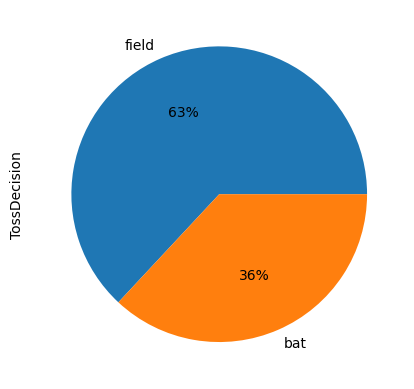

In [11]:
# Create a Pie Chart of 'TossDecision' column

ipl_matches['TossDecision'].value_counts().plot(kind = 'pie', autopct = '%d%%')

In [12]:
# Find how many matches each team played

team1 = ipl_matches['Team1'].value_counts()
team2 = ipl_matches['Team2'].value_counts()

(team1 + team2).sort_values(ascending = False)

Mumbai Indians                 231
Royal Challengers Bangalore    226
Kolkata Knight Riders          223
Chennai Super Kings            208
Rajasthan Royals               192
Kings XI Punjab                190
Delhi Daredevils               161
Sunrisers Hyderabad            152
Deccan Chargers                 75
Delhi Capitals                  63
Pune Warriors                   46
Gujarat Lions                   30
Punjab Kings                    28
Gujarat Titans                  16
Rising Pune Supergiant          16
Lucknow Super Giants            15
Kochi Tuskers Kerala            14
Rising Pune Supergiants         14
dtype: int64

# 2) `sort_values`: (series and dataframe)
`Parameters:` ascending, na_position, inplace, multiple cols

In [13]:
s = pd.Series([1, 5, 7, 9, 5, 3, 4, 6, 2, 8])

s.sort_values()

0    1
8    2
5    3
6    4
1    5
4    5
7    6
2    7
9    8
3    9
dtype: int64

In [14]:
# On dataframe

movies = pd.read_csv(r'00 movies.csv')

movies.head()

,title_x,imdb_id,poster_path,wiki_link,title_y,original_title,is_adult,year_of_release,runtime,genres,imdb_rating,imdb_votes,story,summary,tagline,actors,wins_nominations,release_date
0,Uri: The Surgical Strike,tt8291224,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Uri:_The_Surgica...,Uri: The Surgical Strike,Uri: The Surgical Strike,0,2019,138,Action|Drama|War,8.4,35112,Divided over five chapters the film chronicle...,Indian army special forces execute a covert op...,NaN,Vicky Kaushal|Paresh Rawal|Mohit Raina|Yami Ga...,4 wins,11 January 2019 (USA)
1,Battalion 609,tt9472208,NaN,https://en.wikipedia.org/wiki/Battalion_609,Battalion 609,Battalion 609,0,2019,131,War,4.1,73,The story revolves around a cricket match betw...,The story of Battalion 609 revolves around a c...,NaN,Vicky Ahuja|Shoaib Ibrahim|Shrikant Kamat|Elen...,NaN,11 January 2019 (India)
2,The Accidental Prime Minister (film),tt6986710,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/The_Accidental_P...,The Accidental Prime Minister,The Accidental Prime Minister,0,2019,112,Biography|Drama,6.1,5549,Based on the memoir by Indian policy analyst S...,Explores Manmohan Singh's tenure as the Prime ...,NaN,Anupam Kher|Akshaye Khanna|Aahana Kumra|Atul S...,NaN,11 January 2019 (USA)
3,Why Cheat India,tt8108208,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Why_Cheat_India,Why Cheat India,Why Cheat India,0,2019,121,Crime|Drama,6.0,1891,The movie focuses on existing malpractices in ...,The movie focuses on existing malpractices in ...,NaN,Emraan Hashmi|Shreya Dhanwanthary|Snighdadeep ...,NaN,18 January 2019 (USA)
4,Evening Shadows,tt6028796,NaN,https://en.wikipedia.org/wiki/Evening_Shadows,Evening Shadows,Evening Shadows,0,2018,102,Drama,7.3,280,While gay rights and marriage equality has bee...,Under the 'Evening Shadows' truth often plays...,NaN,Mona Ambegaonkar|Ananth Narayan Mahadevan|Deva...,17 wins & 1 nomination,11 January 2019 (India)


In [15]:
# On single column (Series)

movies.sort_values('title_x')

,title_x,imdb_id,poster_path,wiki_link,title_y,original_title,is_adult,year_of_release,runtime,genres,imdb_rating,imdb_votes,story,summary,tagline,actors,wins_nominations,release_date
1498,16 December (film),tt0313844,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/16_December_(film),16-Dec,16-Dec,0,2002,158,Action|Thriller,6.9,1091,16 December 1971 was the day when India won t...,Indian intelligence agents race against time t...,NaN,Danny Denzongpa|Gulshan Grover|Milind Soman|Di...,2 nominations,22 March 2002 (India)
1021,1920 (film),tt1301698,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/1920_(film),1920,1920,0,2008,138,Horror|Mystery|Romance,6.4,2588,A devotee of Bhagwan Shri Hanuman Arjun Singh...,After forsaking his family and religion a hus...,A Love Made in Heaven...A Revenge Born in Hell...,Rajniesh Duggall|Adah Sharma|Anjori Alagh|Raj ...,NaN,12 September 2008 (India)
287,1920: London,tt5638500,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/1920_London,1920 London,1920 London,0,2016,120,Horror|Mystery,4.1,1373,Shivangi (Meera Chopra) lives in London with h...,After her husband is possessed by an evil spir...,Fear strikes again,Sharman Joshi|Meera Chopra|Vishal Karwal|Suren...,NaN,6 May 2016 (USA)
723,1920: The Evil Returns,tt2222550,https://upload.wikimedia.org/wikipedia/en/e/e7...,https://en.wikipedia.org/wiki/1920:_The_Evil_R...,1920: Evil Returns,1920: Evil Returns,0,2012,124,Drama|Horror|Romance,4.8,1587,This story revolves around a famous poet who m...,This story revolves around a famous poet who m...,Possession is back,Vicky Ahuja|Tia Bajpai|Irma Jämhammar|Sharad K...,NaN,2 November 2012 (India)
1039,1971 (2007 film),tt0983990,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/1971_(2007_film),1971,1971,0,2007,160,Action|Drama|War,7.9,1121,Based on true facts the film revolves around ...,Based on true facts the film revolves around ...,Honor the heroes.......,Manoj Bajpayee|Ravi Kishan|Deepak Dobriyal|,1 win,9 March 2007 (India)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
778,Zindagi Na Milegi Dobara,tt1562872,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Zindagi_Na_Mileg...,Zindagi Na Milegi Dobara,Zindagi Na Milegi Dobara,0,2011,155,Comedy|Drama,8.1,60826,Three friends decide to turn their fantasy vac...,Three friends decide to turn their fantasy vac...,NaN,Hrithik Roshan|Farhan Akhtar|Abhay Deol|Katrin...,30 wins & 22 nominations,15 July 2011 (India)
670,Zindagi Tere Naam,tt2164702,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Zindagi_Tere_Naam,Zindagi Tere Naam,Zindagi Tere Naam,0,2012,120,Romance,4.7,27,Mr. Singh an elderly gentleman relates to hi...,Mr. Singh an elderly gentleman relates to hi...,NaN,Mithun Chakraborty|Ranjeeta Kaur|Priyanka Meht...,1 win,16 March 2012 (India)
756,Zokkomon,tt1605790,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Zokkomon,Zokkomon,Zokkomon,0,2011,109,Action|Adventure,4.0,274,After the passing of his parents in an acciden...,An orphan is abused and abandoned believed to...,Betrayal. Friendship. Bravery.,Darsheel Safary|Anupam Kher|Manjari Fadnnis|Ti...,NaN,22 April 2011 (India)
939,Zor Lagaa Ke...Haiya!,tt1479857,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Zor_Lagaa_Ke...H...,Zor Lagaa Ke... Haiya!,Zor Lagaa Ke... Haiya!,0,2009,\N,Comedy|Drama|Family,6.4,46,A tree narrates the story of four Mumbai-based...,Children build a tree-house to spy on a beggar...,NaN,Meghan Jadhav|Mithun Chakraborty|Riya Sen|Seem...,NaN,NaN


In [16]:
# See what happens when there are missing values in a dataset.

students = pd.DataFrame(
    {
        'name':['nitish','ankit','rupesh',np.nan,'mrityunjay',np.nan,'rishabh',np.nan,'aditya',np.nan],
        'college':['bit','iit','vit',np.nan,np.nan,'vlsi','ssit',np.nan,np.nan,'git'],
        'branch':['eee','it','cse',np.nan,'me','ce','civ','cse','bio',np.nan],
        'cgpa':[6.66,8.25,6.41,np.nan,5.6,9.0,7.4,10,7.4,np.nan],
        'package':[4,5,6,np.nan,6,7,8,9,np.nan,np.nan]

    }
)

students

,name,college,branch,cgpa,package
0,nitish,bit,eee,6.66,4.0
1,ankit,iit,it,8.25,5.0
2,rupesh,vit,cse,6.41,6.0
3,NaN,NaN,NaN,NaN,NaN
4,mrityunjay,NaN,me,5.60,6.0
5,NaN,vlsi,ce,9.00,7.0
6,rishabh,ssit,civ,7.40,8.0
7,NaN,NaN,cse,10.00,9.0
8,aditya,NaN,bio,7.40,NaN
9,NaN,git,NaN,NaN,NaN


In [17]:
students.sort_values(by = 'name')

# See by default missing values goes last
# But we can also have them on the top.
# See the below code

,name,college,branch,cgpa,package
8,aditya,NaN,bio,7.40,NaN
1,ankit,iit,it,8.25,5.0
4,mrityunjay,NaN,me,5.60,6.0
0,nitish,bit,eee,6.66,4.0
6,rishabh,ssit,civ,7.40,8.0
2,rupesh,vit,cse,6.41,6.0
3,NaN,NaN,NaN,NaN,NaN
5,NaN,vlsi,ce,9.00,7.0
7,NaN,NaN,cse,10.00,9.0
9,NaN,git,NaN,NaN,NaN


In [18]:
students.sort_values(by = 'name', na_position = 'first')


,name,college,branch,cgpa,package
3,NaN,NaN,NaN,NaN,NaN
5,NaN,vlsi,ce,9.00,7.0
7,NaN,NaN,cse,10.00,9.0
9,NaN,git,NaN,NaN,NaN
8,aditya,NaN,bio,7.40,NaN
1,ankit,iit,it,8.25,5.0
4,mrityunjay,NaN,me,5.60,6.0
0,nitish,bit,eee,6.66,4.0
6,rishabh,ssit,civ,7.40,8.0
2,rupesh,vit,cse,6.41,6.0


In [19]:
movies.sort_values(by = ['year_of_release', 'title_x'])

,title_x,imdb_id,poster_path,wiki_link,title_y,original_title,is_adult,year_of_release,runtime,genres,imdb_rating,imdb_votes,story,summary,tagline,actors,wins_nominations,release_date
1575,Aalavandhan,tt0294264,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Aalavandhan,Aalavandhan,Aalavandhan,0,2001,177,Action|Thriller,7.1,1746,The story follows Abhay (Haasan) who has a dis...,A psychopath tries to protect his twin brother...,The Fearless,Kamal Haasan|Raveena Tandon|Manisha Koirala|Ki...,1 win & 1 nomination,16 November 2001 (India)
1576,Aamdani Atthanni Kharcha Rupaiya,tt0305173,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Aamdani_Atthanni...,Aamdani Atthanni Kharcha Rupaiya,Aamdani Atthanni Kharcha Rupaiya,0,2001,150,Comedy|Drama|Family,4.7,1026,Jhoomri and her husband Bhimsha move into a ...,In order to make ends meet three women steps ...,NaN,Govinda|Juhi Chawla|Tabu|Chandrachur Singh|Joh...,1 nomination,21 December 2001 (India)
1577,Aashiq (2001 film),tt0273406,https://upload.wikimedia.org/wikipedia/en/c/c6...,https://en.wikipedia.org/wiki/Aashiq_(2001_film),Aashiq,Aashiq,0,2001,160,Action|Drama|Romance,3.8,357,Pooja and Chander Kapoor have a heart-to-heart...,Pooja and Chander Kapoor have a heart-to-heart...,NaN,Bobby Deol|Karisma Kapoor|,NaN,26 January 2001 (India)
1579,Ajnabee (2001 film),tt0278291,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Ajnabee_(2001_film),Ajnabee,Ajnabee,0,2001,165,Action|Crime|Drama,6.3,7480,A new couple get married and move to Switzerla...,Bobby Deol and Kareena Kapoor play a new coupl...,Trust no one,Akshay Kumar|Bobby Deol|Kareena Kapoor|Bipasha...,3 wins & 9 nominations,21 September 2001 (India)
1578,Aks (2001 film),tt0289845,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Aks_(2001_film),Aks,Aks,0,2001,184,Action|Crime|Horror,5.9,1518,Aks is the story of a hunter and his prey. A c...,Raghavan Ghatge a psychotic terrorist and Ma...,There is a stranger in your mirror,Amitabh Bachchan|Raveena Tandon|Manoj Bajpayee...,9 wins & 14 nominations,13 July 2001 (India)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
64,Ujda Chaman,tt11046300,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Ujda_Chaman,Ujda Chaman,Ujda Chaman,0,2019,120,Comedy,8.1,1440,Ujda Chaman is about a 30 -year-old bachelor C...,Ujda Chaman is about a 30 -year-old bachelor C...,NaN,Sunny Singh Nijjar|Maanvi Gagroo|Saurabh Shukl...,NaN,1 November 2019 (USA)
0,Uri: The Surgical Strike,tt8291224,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Uri:_The_Surgica...,Uri: The Surgical Strike,Uri: The Surgical Strike,0,2019,138,Action|Drama|War,8.4,35112,Divided over five chapters the film chronicle...,Indian army special forces execute a covert op...,NaN,Vicky Kaushal|Paresh Rawal|Mohit Raina|Yami Ga...,4 wins,11 January 2019 (USA)
3,Why Cheat India,tt8108208,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Why_Cheat_India,Why Cheat India,Why Cheat India,0,2019,121,Crime|Drama,6.0,1891,The movie focuses on existing malpractices in ...,The movie focuses on existing malpractices in ...,NaN,Emraan Hashmi|Shreya Dhanwanthary|Snighdadeep ...,NaN,18 January 2019 (USA)
60,Yaaram (2019 film),tt11007050,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Yaaram_(2019_film),#Yaaram,#Yaaram,0,2019,\N,Comedy|Romance,5.7,7,All set for an arranged marriage Rohit Bajaj ...,All set for an arranged marriage Rohit Bajaj ...,NaN,Siddhanth Kapoor|Prateik|Anita Raj|Ishita Raj|...,NaN,NaN


In [20]:
# What if i want such that year should be sorted in ascending and title on descending?

movies.sort_values(by = ['year_of_release', 'title_x'], ascending = [True, False])

# Now year will be from 2001 and title will start from 'Z'

,title_x,imdb_id,poster_path,wiki_link,title_y,original_title,is_adult,year_of_release,runtime,genres,imdb_rating,imdb_votes,story,summary,tagline,actors,wins_nominations,release_date
1623,Zubeidaa,tt0255713,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Zubeidaa,Zubeidaa,Zubeidaa,0,2001,153,Biography|Drama|History,6.2,1384,The film begins with Riyaz (Rajat Kapoor) Zub...,Zubeidaa an aspiring Muslim actress marries ...,The Story of a Princess,Karisma Kapoor|Rekha|Manoj Bajpayee|Rajit Kapo...,3 wins & 13 nominations,19 January 2001 (India)
1625,Yeh Zindagi Ka Safar,tt0298607,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Yeh_Zindagi_Ka_S...,Yeh Zindagi Ka Safar,Yeh Zindagi Ka Safar,0,2001,146,Drama,3.0,133,Hindi pop-star Sarina Devan lives a wealthy ...,A singer finds out she was adopted when the ed...,NaN,Ameesha Patel|Jimmy Sheirgill|Nafisa Ali|Gulsh...,NaN,16 November 2001 (India)
1622,Yeh Teraa Ghar Yeh Meraa Ghar,tt0298606,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Yeh_Teraa_Ghar_Y...,Yeh Teraa Ghar Yeh Meraa Ghar,Yeh Teraa Ghar Yeh Meraa Ghar,0,2001,175,Comedy|Drama,5.7,704,In debt; Dayashankar Pandey is forced to go to...,In debt; Dayashankar Pandey is forced to go to...,NaN,Sunil Shetty|Mahima Chaudhry|Paresh Rawal|Saur...,1 nomination,12 October 2001 (India)
1620,Yeh Raaste Hain Pyaar Ke,tt0292740,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Yeh_Raaste_Hain_...,Yeh Raaste Hain Pyaar Ke,Yeh Raaste Hain Pyaar Ke,0,2001,149,Drama|Romance,4.0,607,Two con artistes and car thieves Vicky (Ajay ...,Two con artistes and car thieves Vicky (Ajay ...,Love is a journey... not a destination,Ajay Devgn|Madhuri Dixit|Preity Zinta|Vikram G...,NaN,10 August 2001 (India)
1573,Yaadein (2001 film),tt0248617,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Yaadein_(2001_film),Yaadein...,Yaadein...,0,2001,171,Drama|Musical|Romance,4.4,3034,Raj Singh Puri is best friends with L.K. Malho...,Raj Singh Puri is best friends with L.K. Malho...,memories to cherish...,Jackie Shroff|Hrithik Roshan|Kareena Kapoor|Am...,1 nomination,27 June 2001 (India)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
37,Article 15 (film),tt10324144,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Article_15_(film),Article 15,Article 15,0,2019,130,Crime|Drama,8.3,13417,In the rural heartlands of India an upright p...,In the rural heartlands of India an upright p...,Farq Bahut Kar Liya| Ab Farq Laayenge.,Ayushmann Khurrana|Nassar|Manoj Pahwa|Kumud Mi...,1 win,28 June 2019 (USA)
46,Arjun Patiala,tt7881524,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Arjun_Patiala,Arjun Patiala,Arjun Patiala,0,2019,107,Action|Comedy,4.1,676,Arjun Patiala(Diljit Dosanjh)has recently been...,This spoof comedy narrates the story of a cop ...,NaN,Diljit Dosanjh|Kriti Sanon|Varun Sharma|Ronit ...,NaN,26 July 2019 (USA)
10,Amavas,tt8396186,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Amavas,Amavas,Amavas,0,2019,134,Horror|Thriller,2.8,235,Far away from the bustle of the city a young ...,The lives of a couple turn into a nightmare a...,NaN,Ali Asgar|Vivan Bhatena|Nargis Fakhri|Sachiin ...,NaN,8 February 2019 (India)
26,Albert Pinto Ko Gussa Kyun Aata Hai?,tt4355838,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Albert_Pinto_Ko_...,Albert Pinto Ko Gussa Kyun Aata Hai?,Albert Pinto Ko Gussa Kyun Aata Hai?,0,2019,100,Drama,4.8,56,Albert leaves his house one morning without te...,Albert Pinto goes missing one day and his girl...,NaN,Manav Kaul|Nandita Das|,NaN,12 April 2019 (India)


# 3) `rank()`: (Series)

This gives ranks to the column. For eg: in below dataset, if we find rank of batter, the batter who made the highest runs rill get rank 1 and the one with lowest runs, will get the last rank and so onn.

`Remember`: Here it's reverse. The one who made highest runs, will reveive last rank and for lowest rank will receive first rank
Here also we have **ascending** parameter

This is same as we get the rank in exam.

In [21]:
batsman = pd.read_csv(f'00 batsman_runs_ipl.csv')

batsman.head()

,batter,batsman_run
0,A Ashish Reddy,280
1,A Badoni,161
2,A Chandila,4
3,A Chopra,53
4,A Choudhary,25


In [22]:
batsman['rank'] = batsman['batsman_run'].rank(ascending = False)

batsman.head()

,batter,batsman_run,rank
0,A Ashish Reddy,280,166.5
1,A Badoni,161,226.0
2,A Chandila,4,535.0
3,A Chopra,53,329.0
4,A Choudhary,25,402.5


In [23]:
# sortung based on runs

batsman.sort_values('rank')

,batter,batsman_run,rank
569,V Kohli,6634,1.0
462,S Dhawan,6244,2.0
130,DA Warner,5883,3.0
430,RG Sharma,5881,4.0
493,SK Raina,5536,5.0
...,...,...,...
512,SS Cottrell,0,594.0
466,S Kaushik,0,594.0
203,IC Pandey,0,594.0
467,S Ladda,0,594.0


# 4) `sort_index()`: Series and DataFrame

Sorts the indices

In [24]:
data = {
    'maths': 85,
    'english': 62,
    'gujarati': 58,
    'social': 75,
}

marks = pd.Series(data)
marks

maths       85
english     62
gujarati    58
social      75
dtype: int64

In [25]:
# sort_index()

marks.sort_index()

english     62
gujarati    58
maths       85
social      75
dtype: int64

In [26]:
movies.sort_index(ascending = False)

,title_x,imdb_id,poster_path,wiki_link,title_y,original_title,is_adult,year_of_release,runtime,genres,imdb_rating,imdb_votes,story,summary,tagline,actors,wins_nominations,release_date
1628,Humsafar,tt2403201,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Humsafar,Humsafar,Humsafar,0,2011,35,Drama|Romance,9.0,2968,Sara and Ashar are childhood friends who share...,Ashar and Khirad are forced to get married due...,NaN,Fawad Khan|,NaN,TV Series (2011–2012)
1627,Daaka,tt10833860,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Daaka,Daaka,Daaka,0,2019,136,Action,7.4,38,Shinda tries robbing a bank so he can be wealt...,Shinda tries robbing a bank so he can be wealt...,NaN,Gippy Grewal|Zareen Khan|,NaN,1 November 2019 (USA)
1626,Sabse Bada Sukh,tt0069204,NaN,https://en.wikipedia.org/wiki/Sabse_Bada_Sukh,Sabse Bada Sukh,Sabse Bada Sukh,0,2018,\N,Comedy|Drama,6.1,13,Village born Lalloo re-locates to Bombay and ...,Village born Lalloo re-locates to Bombay and ...,NaN,Vijay Arora|Asrani|Rajni Bala|Kumud Damle|Utpa...,NaN,NaN
1625,Yeh Zindagi Ka Safar,tt0298607,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Yeh_Zindagi_Ka_S...,Yeh Zindagi Ka Safar,Yeh Zindagi Ka Safar,0,2001,146,Drama,3.0,133,Hindi pop-star Sarina Devan lives a wealthy ...,A singer finds out she was adopted when the ed...,NaN,Ameesha Patel|Jimmy Sheirgill|Nafisa Ali|Gulsh...,NaN,16 November 2001 (India)
1624,Tera Mera Saath Rahen,tt0301250,https://upload.wikimedia.org/wikipedia/en/2/2b...,https://en.wikipedia.org/wiki/Tera_Mera_Saath_...,Tera Mera Saath Rahen,Tera Mera Saath Rahen,0,2001,148,Drama,4.9,278,Raj Dixit lives with his younger brother Rahu...,A man is torn between his handicapped brother ...,NaN,Ajay Devgn|Sonali Bendre|Namrata Shirodkar|Pre...,NaN,7 November 2001 (India)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4,Evening Shadows,tt6028796,NaN,https://en.wikipedia.org/wiki/Evening_Shadows,Evening Shadows,Evening Shadows,0,2018,102,Drama,7.3,280,While gay rights and marriage equality has bee...,Under the 'Evening Shadows' truth often plays...,NaN,Mona Ambegaonkar|Ananth Narayan Mahadevan|Deva...,17 wins & 1 nomination,11 January 2019 (India)
3,Why Cheat India,tt8108208,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Why_Cheat_India,Why Cheat India,Why Cheat India,0,2019,121,Crime|Drama,6.0,1891,The movie focuses on existing malpractices in ...,The movie focuses on existing malpractices in ...,NaN,Emraan Hashmi|Shreya Dhanwanthary|Snighdadeep ...,NaN,18 January 2019 (USA)
2,The Accidental Prime Minister (film),tt6986710,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/The_Accidental_P...,The Accidental Prime Minister,The Accidental Prime Minister,0,2019,112,Biography|Drama,6.1,5549,Based on the memoir by Indian policy analyst S...,Explores Manmohan Singh's tenure as the Prime ...,NaN,Anupam Kher|Akshaye Khanna|Aahana Kumra|Atul S...,NaN,11 January 2019 (USA)
1,Battalion 609,tt9472208,NaN,https://en.wikipedia.org/wiki/Battalion_609,Battalion 609,Battalion 609,0,2019,131,War,4.1,73,The story revolves around a cricket match betw...,The story of Battalion 609 revolves around a c...,NaN,Vicky Ahuja|Shoaib Ibrahim|Shrikant Kamat|Elen...,NaN,11 January 2019 (India)


# 5) `set_index():` Dataframe

Used to make any column of the dataframe as index.

In [27]:
batsman.set_index('batter', inplace = True)

batsman

,batsman_run,rank
batter,,
A Ashish Reddy,280,166.5
A Badoni,161,226.0
A Chandila,4,535.0
A Chopra,53,329.0
A Choudhary,25,402.5
...,...,...
Yash Dayal,0,594.0
Yashpal Singh,47,343.0
Younis Khan,3,547.5


# 6) `reset_index()`: Series and Dataframe

Resets the index to original.

In [28]:
batsman

,batsman_run,rank
batter,,
A Ashish Reddy,280,166.5
A Badoni,161,226.0
A Chandila,4,535.0
A Chopra,53,329.0
A Choudhary,25,402.5
...,...,...
Yash Dayal,0,594.0
Yashpal Singh,47,343.0
Younis Khan,3,547.5


In [29]:
batsman.reset_index()

,batter,batsman_run,rank
0,A Ashish Reddy,280,166.5
1,A Badoni,161,226.0
2,A Chandila,4,535.0
3,A Chopra,53,329.0
4,A Choudhary,25,402.5
...,...,...,...
600,Yash Dayal,0,594.0
601,Yashpal Singh,47,343.0
602,Younis Khan,3,547.5
603,Yuvraj Singh,2754,27.0


In [30]:
# What if we want to make some other column as an index and make this 'batter, which is an existing index, again a column?
# See the code

batsman.set_index('rank')

# See, this made 'rank' as a new index but removed 'batter' column.
# Now see the below code

,batsman_run
rank,
166.5,280
226.0,161
535.0,4
329.0,53
402.5,25
...,...
594.0,0
343.0,47
547.5,3


In [31]:
batsman.reset_index().set_index('rank')

,batter,batsman_run
rank,,
166.5,A Ashish Reddy,280
226.0,A Badoni,161
535.0,A Chandila,4
329.0,A Chopra,53
402.5,A Choudhary,25
...,...,...
594.0,Yash Dayal,0
343.0,Yashpal Singh,47
547.5,Younis Khan,3


In [32]:
# Series

marks

maths       85
english     62
gujarati    58
social      75
dtype: int64

In [33]:
marks.reset_index()

# See, this converted the series to a dataframe
# So when we apply reset_index() to a series, it converts it ti a dataframe.

,index,0
0,maths,85
1,english,62
2,gujarati,58
3,social,75


In [34]:
type(marks.reset_index())

pandas.core.frame.DataFrame

# 7) `rename`: Dataframe

Renames the column and index of the dataframe

In [35]:
# See what happens when there are missing values in a dataset.

students = pd.DataFrame(
    {
        'name':['nitish','ankit','rupesh','harshit','mrityunjay','jenish','rishabh','parth','aditya','khilan'],
        'college':['bit','iit','vit','gmers','psmc','vlsi','ssit','ld','gsms','git'],
        'branch':['eee','it','cse','mbbs','me','ce','civ','cse','bio','mba'],
        'cgpa':[6.66,8.25,6.41,8,5.6,9.0,7.4,10,7.4,7.8],
        'package':[4,5,6,10,6,7,8,9,11,9.5]

    }
)

students

,name,college,branch,cgpa,package
0,nitish,bit,eee,6.66,4.0
1,ankit,iit,it,8.25,5.0
2,rupesh,vit,cse,6.41,6.0
3,harshit,gmers,mbbs,8.00,10.0
4,mrityunjay,psmc,me,5.60,6.0
5,jenish,vlsi,ce,9.00,7.0
6,rishabh,ssit,civ,7.40,8.0
7,parth,ld,cse,10.00,9.0
8,aditya,gsms,bio,7.40,11.0
9,khilan,git,mba,7.80,9.5


In [36]:
# Change column names
# name to student and college to institute

column = {
    'name': 'student',
    'college': 'institute'
}

students.rename(columns = column, inplace = True)

students

,student,institute,branch,cgpa,package
0,nitish,bit,eee,6.66,4.0
1,ankit,iit,it,8.25,5.0
2,rupesh,vit,cse,6.41,6.0
3,harshit,gmers,mbbs,8.00,10.0
4,mrityunjay,psmc,me,5.60,6.0
5,jenish,vlsi,ce,9.00,7.0
6,rishabh,ssit,civ,7.40,8.0
7,parth,ld,cse,10.00,9.0
8,aditya,gsms,bio,7.40,11.0
9,khilan,git,mba,7.80,9.5


In [37]:
# renaming index

students.set_index('student', inplace = True)

students

,institute,branch,cgpa,package
student,,,,
nitish,bit,eee,6.66,4.0
ankit,iit,it,8.25,5.0
rupesh,vit,cse,6.41,6.0
harshit,gmers,mbbs,8.00,10.0
mrityunjay,psmc,me,5.60,6.0
jenish,vlsi,ce,9.00,7.0
rishabh,ssit,civ,7.40,8.0
parth,ld,cse,10.00,9.0
aditya,gsms,bio,7.40,11.0


In [38]:
indx = {
    'ankit': 'nikunj',
    'rupesh': 'jugal'
}

students.rename(index = indx, inplace = 1)

students

,institute,branch,cgpa,package
student,,,,
nitish,bit,eee,6.66,4.0
nikunj,iit,it,8.25,5.0
jugal,vit,cse,6.41,6.0
harshit,gmers,mbbs,8.00,10.0
mrityunjay,psmc,me,5.60,6.0
jenish,vlsi,ce,9.00,7.0
rishabh,ssit,civ,7.40,8.0
parth,ld,cse,10.00,9.0
aditya,gsms,bio,7.40,11.0


# 8) `unique()`: Series

Returns all the unique values of the Series

In [39]:
data = [1, 2, 3, 4, 5, 1, 2, 5, 55, 45, 65, 75, np.nan, np.nan, np.nan]

pd.Series(data).unique()

array([ 1.,  2.,  3.,  4.,  5., 55., 45., 65., 75., nan])

In [40]:
ipl_matches['Season'].unique()

array(['2022', '2021', '2020/21', '2019', '2018', '2017', '2016', '2015',
       '2014', '2013', '2012', '2011', '2009/10', '2009', '2007/08'],
      dtype=object)

In [41]:
# No.of total season in the ipl

ipl_matches['Season'].unique().shape[0]

15

# 9) `nunique()`: returns number of unique items. 
# `It doesn't count nan values`.

In [42]:
ipl_matches['Season'].nunique()

15

In [43]:
data = [1, 2, 3, 4, 5, 1, 2, 5, 55, 45, 65, 75, np.nan, np.nan, np.nan]

pd.Series(data).unique().shape[0]

10

In [44]:
pd.Series(data).nunique()

# Doesn't count nan values

9

# 10) `isnull()`: Series and Dataframe

Returns True if the value is missing else False. <br>
It asks, **If value is nan?**

In [45]:
movies

,title_x,imdb_id,poster_path,wiki_link,title_y,original_title,is_adult,year_of_release,runtime,genres,imdb_rating,imdb_votes,story,summary,tagline,actors,wins_nominations,release_date
0,Uri: The Surgical Strike,tt8291224,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Uri:_The_Surgica...,Uri: The Surgical Strike,Uri: The Surgical Strike,0,2019,138,Action|Drama|War,8.4,35112,Divided over five chapters the film chronicle...,Indian army special forces execute a covert op...,NaN,Vicky Kaushal|Paresh Rawal|Mohit Raina|Yami Ga...,4 wins,11 January 2019 (USA)
1,Battalion 609,tt9472208,NaN,https://en.wikipedia.org/wiki/Battalion_609,Battalion 609,Battalion 609,0,2019,131,War,4.1,73,The story revolves around a cricket match betw...,The story of Battalion 609 revolves around a c...,NaN,Vicky Ahuja|Shoaib Ibrahim|Shrikant Kamat|Elen...,NaN,11 January 2019 (India)
2,The Accidental Prime Minister (film),tt6986710,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/The_Accidental_P...,The Accidental Prime Minister,The Accidental Prime Minister,0,2019,112,Biography|Drama,6.1,5549,Based on the memoir by Indian policy analyst S...,Explores Manmohan Singh's tenure as the Prime ...,NaN,Anupam Kher|Akshaye Khanna|Aahana Kumra|Atul S...,NaN,11 January 2019 (USA)
3,Why Cheat India,tt8108208,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Why_Cheat_India,Why Cheat India,Why Cheat India,0,2019,121,Crime|Drama,6.0,1891,The movie focuses on existing malpractices in ...,The movie focuses on existing malpractices in ...,NaN,Emraan Hashmi|Shreya Dhanwanthary|Snighdadeep ...,NaN,18 January 2019 (USA)
4,Evening Shadows,tt6028796,NaN,https://en.wikipedia.org/wiki/Evening_Shadows,Evening Shadows,Evening Shadows,0,2018,102,Drama,7.3,280,While gay rights and marriage equality has bee...,Under the 'Evening Shadows' truth often plays...,NaN,Mona Ambegaonkar|Ananth Narayan Mahadevan|Deva...,17 wins & 1 nomination,11 January 2019 (India)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1624,Tera Mera Saath Rahen,tt0301250,https://upload.wikimedia.org/wikipedia/en/2/2b...,https://en.wikipedia.org/wiki/Tera_Mera_Saath_...,Tera Mera Saath Rahen,Tera Mera Saath Rahen,0,2001,148,Drama,4.9,278,Raj Dixit lives with his younger brother Rahu...,A man is torn between his handicapped brother ...,NaN,Ajay Devgn|Sonali Bendre|Namrata Shirodkar|Pre...,NaN,7 November 2001 (India)
1625,Yeh Zindagi Ka Safar,tt0298607,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Yeh_Zindagi_Ka_S...,Yeh Zindagi Ka Safar,Yeh Zindagi Ka Safar,0,2001,146,Drama,3.0,133,Hindi pop-star Sarina Devan lives a wealthy ...,A singer finds out she was adopted when the ed...,NaN,Ameesha Patel|Jimmy Sheirgill|Nafisa Ali|Gulsh...,NaN,16 November 2001 (India)
1626,Sabse Bada Sukh,tt0069204,NaN,https://en.wikipedia.org/wiki/Sabse_Bada_Sukh,Sabse Bada Sukh,Sabse Bada Sukh,0,2018,\N,Comedy|Drama,6.1,13,Village born Lalloo re-locates to Bombay and ...,Village born Lalloo re-locates to Bombay and ...,NaN,Vijay Arora|Asrani|Rajni Bala|Kumud Damle|Utpa...,NaN,NaN
1627,Daaka,tt10833860,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Daaka,Daaka,Daaka,0,2019,136,Action,7.4,38,Shinda tries robbing a bank so he can be wealt...,Shinda tries robbing a bank so he can be wealt...,NaN,Gippy Grewal|Zareen Khan|,NaN,1 November 2019 (USA)


In [46]:
# Series

movies['release_date'].isnull()

0       False
1       False
2       False
3       False
4       False
        ...  
1624    False
1625    False
1626     True
1627    False
1628    False
Name: release_date, Length: 1629, dtype: bool

In [47]:
movies['release_date'].isnull().sum()

107

In [48]:
# DataFrame

movies.isnull()

,title_x,imdb_id,poster_path,wiki_link,title_y,original_title,is_adult,year_of_release,runtime,genres,imdb_rating,imdb_votes,story,summary,tagline,actors,wins_nominations,release_date
0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False
1,False,False,True,False,False,False,False,False,False,False,False,False,False,False,True,False,True,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,True,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,True,False
4,False,False,True,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1624,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,True,False
1625,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,True,False
1626,False,False,True,False,False,False,False,False,False,False,False,False,False,False,True,False,True,True
1627,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,True,False


In [49]:
movies.isnull().sum()

title_x                0
imdb_id                0
poster_path          103
wiki_link              0
title_y                0
original_title         0
is_adult               0
year_of_release        0
runtime                0
genres                 0
imdb_rating            0
imdb_votes             0
story                 20
summary                0
tagline             1072
actors                 5
wins_nominations     922
release_date         107
dtype: int64

# 11) `notnull()`: Series and Dataframe

This is reverse of isnull(). It asks, `Are you not null? (Means, are you filled?) <br>
So where the value is filled, it returns True and False where value is missing

In [50]:
# Series

movies['release_date'].notnull()

0        True
1        True
2        True
3        True
4        True
        ...  
1624     True
1625     True
1626    False
1627     True
1628     True
Name: release_date, Length: 1629, dtype: bool

In [51]:
len(movies)

# See length of movies is 1629 and in previous code, we saw there were 107 missing values for 'release_date'
# Hence notnull() should give 1629 - 107 = 1522

1629

In [52]:
movies['release_date'].notnull().sum()

# See, this means there're 1522 filled values

1522

In [53]:
# DataFrame

movies.notnull()

,title_x,imdb_id,poster_path,wiki_link,title_y,original_title,is_adult,year_of_release,runtime,genres,imdb_rating,imdb_votes,story,summary,tagline,actors,wins_nominations,release_date
0,True,True,True,True,True,True,True,True,True,True,True,True,True,True,False,True,True,True
1,True,True,False,True,True,True,True,True,True,True,True,True,True,True,False,True,False,True
2,True,True,True,True,True,True,True,True,True,True,True,True,True,True,False,True,False,True
3,True,True,True,True,True,True,True,True,True,True,True,True,True,True,False,True,False,True
4,True,True,False,True,True,True,True,True,True,True,True,True,True,True,False,True,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1624,True,True,True,True,True,True,True,True,True,True,True,True,True,True,False,True,False,True
1625,True,True,True,True,True,True,True,True,True,True,True,True,True,True,False,True,False,True
1626,True,True,False,True,True,True,True,True,True,True,True,True,True,True,False,True,False,False
1627,True,True,True,True,True,True,True,True,True,True,True,True,True,True,False,True,False,True


In [54]:
movies.notnull().sum()

title_x             1629
imdb_id             1629
poster_path         1526
wiki_link           1629
title_y             1629
original_title      1629
is_adult            1629
year_of_release     1629
runtime             1629
genres              1629
imdb_rating         1629
imdb_votes          1629
story               1609
summary             1629
tagline              557
actors              1624
wins_nominations     707
release_date        1522
dtype: int64

In [55]:
(movies['release_date'][movies['release_date'].isnull()])

48      NaN
60      NaN
67      NaN
70      NaN
71      NaN
       ... 
1591    NaN
1595    NaN
1598    NaN
1606    NaN
1626    NaN
Name: release_date, Length: 107, dtype: object

In [56]:
movies[movies['release_date'].isnull()]    ['release_date']

48      NaN
60      NaN
67      NaN
70      NaN
71      NaN
       ... 
1591    NaN
1595    NaN
1598    NaN
1606    NaN
1626    NaN
Name: release_date, Length: 107, dtype: object

# 12) `hasnans`: Series

It returns True if the specified column has any missing value as False if not. <br>
It asks, **If column has nans?**

In [57]:
# Series

print(movies['release_date'].hasnans)    # Has missing values

print(movies['actors'].hasnans)    # Has missing value

print(movies['wiki_link'].hasnans)    # No missing value

True
True
False


# `Note`: You don't need to remember all 3 of these. You can do everything with **isnull()**

# 13) `dropna()`: Series and Dataframe

Drops the rows having missing values.  <br>

**Parameters**:
1) `axis`; If we pass **axis** parameter as `columns`, it drops the columns with missing values
2) `how`: If any, it drops rows for even a single missing value and if **all**, if drops only those rows where all the values are missing.
3) `subset`: Drop rows if there's missing value in the specified `columns`

In [58]:
# See what happens when there are missing values in a dataset.

students = pd.DataFrame(
    {
        'name':['nitish',np.nan,'rupesh','jenisg','mrityunjay','nikunj','rishabh','parth',np.nan,'khilan'],
        'college':['bit','iit','marwadi','gmers','psmc',np.nan,'ssit','ld','gsms','darshan'],
        'branch':[np.nan,'it','cse','mbbs',np.nan,'ce','civ','cse','bio','mba'],
        'cgpa':[6.66,np.nan,25,np.nan,8,5.6,9.0,8,10,7.4],
        'package':[4,5,6,np.nan,6,7,np.nan,9,11,8.5]

    }
)

students

,name,college,branch,cgpa,package
0,nitish,bit,NaN,6.66,4.0
1,NaN,iit,it,NaN,5.0
2,rupesh,marwadi,cse,25.00,6.0
3,jenisg,gmers,mbbs,NaN,NaN
4,mrityunjay,psmc,NaN,8.00,6.0
5,nikunj,NaN,ce,5.60,7.0
6,rishabh,ssit,civ,9.00,NaN
7,parth,ld,cse,8.00,9.0
8,NaN,gsms,bio,10.00,11.0
9,khilan,darshan,mba,7.40,8.5


In [59]:
# Series

students['name'].dropna()

0        nitish
2        rupesh
3        jenisg
4    mrityunjay
5        nikunj
6       rishabh
7         parth
9        khilan
Name: name, dtype: object

In [60]:
students[['name', 'cgpa']].dropna()

,name,cgpa
0,nitish,6.66
2,rupesh,25.00
4,mrityunjay,8.00
5,nikunj,5.60
6,rishabh,9.00
7,parth,8.00
9,khilan,7.40


In [61]:
students['college'].dropna()

0        bit
1        iit
2    marwadi
3      gmers
4       psmc
6       ssit
7         ld
8       gsms
9    darshan
Name: college, dtype: object

In [62]:
# DataFrame

students.dropna()

,name,college,branch,cgpa,package
2,rupesh,marwadi,cse,25.0,6.0
7,parth,ld,cse,8.0,9.0
9,khilan,darshan,mba,7.4,8.5


In [63]:
students

,name,college,branch,cgpa,package
0,nitish,bit,NaN,6.66,4.0
1,NaN,iit,it,NaN,5.0
2,rupesh,marwadi,cse,25.00,6.0
3,jenisg,gmers,mbbs,NaN,NaN
4,mrityunjay,psmc,NaN,8.00,6.0
5,nikunj,NaN,ce,5.60,7.0
6,rishabh,ssit,civ,9.00,NaN
7,parth,ld,cse,8.00,9.0
8,NaN,gsms,bio,10.00,11.0
9,khilan,darshan,mba,7.40,8.5


In [64]:
# Remove rows where 'name' is missing

students.dropna(subset = ['name'])

# See rows 1 and 8 got drop.

,name,college,branch,cgpa,package
0,nitish,bit,NaN,6.66,4.0
2,rupesh,marwadi,cse,25.00,6.0
3,jenisg,gmers,mbbs,NaN,NaN
4,mrityunjay,psmc,NaN,8.00,6.0
5,nikunj,NaN,ce,5.60,7.0
6,rishabh,ssit,civ,9.00,NaN
7,parth,ld,cse,8.00,9.0
9,khilan,darshan,mba,7.40,8.5


# 14) `fillna()`: Series and DataFrame

Fills the missing value with the specified values

In [65]:
# Series

students['cgpa'].fillna(5.5)

0     6.66
1     5.50
2    25.00
3     5.50
4     8.00
5     5.60
6     9.00
7     8.00
8    10.00
9     7.40
Name: cgpa, dtype: float64

In [66]:
students['cgpa'].fillna(students['cgpa'].mean())

0     6.6600
1     9.9575
2    25.0000
3     9.9575
4     8.0000
5     5.6000
6     9.0000
7     8.0000
8    10.0000
9     7.4000
Name: cgpa, dtype: float64

In [67]:
# DataFrame

fill_values = {
    'name': 'N/A',
    'college': students['college'].mode()[0],
    'branch': students['branch'].mode()[0],
    'cgpa': students['cgpa'].mean(),
    'package': students['package'].mean()    
}

fill_values

{'name': 'N/A',
 'college': 'bit',
 'branch': 'cse',
 'cgpa': 9.957500000000001,
 'package': 7.0625}

In [68]:
students.fillna(fill_values)

,name,college,branch,cgpa,package
0,nitish,bit,cse,6.6600,4.0000
1,N/A,iit,it,9.9575,5.0000
2,rupesh,marwadi,cse,25.0000,6.0000
3,jenisg,gmers,mbbs,9.9575,7.0625
4,mrityunjay,psmc,cse,8.0000,6.0000
5,nikunj,bit,ce,5.6000,7.0000
6,rishabh,ssit,civ,9.0000,7.0625
7,parth,ld,cse,8.0000,9.0000
8,N/A,gsms,bio,10.0000,11.0000
9,khilan,darshan,mba,7.4000,8.5000


# 15) `drop_duplicates`: Series and DataFrame

Drops the rows with the duplicate values

`keep` parameter:
If **first(by-default)**, keeps the first occurance of the duplicate row,  <br>
If **last**, keeps the last occurance of the duplicate row.  <br>
If **False**, drops all duplicate rows.

**Remember**: `It consider a row as duplicate only if all the values of that row are same.`  <br>
`Here also we have **subset** parameter.`

In [99]:
data = {
    'Name': ['Nikunj', 'Jugal', 'Harshit', 'Jenish', 'Jugal', 'Harshit', 'Parth', 'Jenish', 'Parth'],
    'Surname': ['Bosamiya', 'Bosamiya', 'Kamani', 'Mer', 'Bosamiya', 'Kamani', 'Paghdar', 'Mer', 'Paghdar'],
    'City': ['Jetpur', 'Rajkot', 'Himmatnagar', 'Anand', 'Rajkot', 'Himmatnagar', 'Jetpur', 'Ahmedabad', 'Vadodara']
}

friends = pd.DataFrame(data)

friends

,Name,Surname,City
0,Nikunj,Bosamiya,Jetpur
1,Jugal,Bosamiya,Rajkot
2,Harshit,Kamani,Himmatnagar
3,Jenish,Mer,Anand
4,Jugal,Bosamiya,Rajkot
5,Harshit,Kamani,Himmatnagar
6,Parth,Paghdar,Jetpur
7,Jenish,Mer,Ahmedabad
8,Parth,Paghdar,Vadodara


In [100]:
# Series

friends['Name'].drop_duplicates()

0     Nikunj
1      Jugal
2    Harshit
3     Jenish
6      Parth
Name: Name, dtype: object

In [101]:
friends[['Name', 'Surname']].drop_duplicates()

,Name,Surname
0,Nikunj,Bosamiya
1,Jugal,Bosamiya
2,Harshit,Kamani
3,Jenish,Mer
6,Parth,Paghdar


In [102]:
# DataFrame

friends.drop_duplicates(keep = 'last')

,Name,Surname,City
0,Nikunj,Bosamiya,Jetpur
3,Jenish,Mer,Anand
4,Jugal,Bosamiya,Rajkot
5,Harshit,Kamani,Himmatnagar
6,Parth,Paghdar,Jetpur
7,Jenish,Mer,Ahmedabad
8,Parth,Paghdar,Vadodara


In [104]:
friends.drop_duplicates(subset = 'Name')

# See in above code, it was not dropping Part Paghdar Vadodara, but here it is dropping bcz we used 'subset = Name'.
# Here it considers only 'Name' column to find the duplicates

,Name,Surname,City
0,Nikunj,Bosamiya,Jetpur
1,Jugal,Bosamiya,Rajkot
2,Harshit,Kamani,Himmatnagar
3,Jenish,Mer,Anand
6,Parth,Paghdar,Jetpur


# Using, `drop_duplicates()` find the last match played by virat kohli in `Delhi`.

In [74]:
ipl_matches.head()

,ID,City,Date,Season,MatchNumber,Team1,Team2,Venue,TossWinner,TossDecision,SuperOver,WinningTeam,WonBy,Margin,method,Player_of_Match,Team1Players,Team2Players,Umpire1,Umpire2
0,1312200,Ahmedabad,2022-05-29,2022,Final,Rajasthan Royals,Gujarat Titans,"Narendra Modi Stadium, Ahmedabad",Rajasthan Royals,bat,N,Gujarat Titans,Wickets,7.0,NaN,HH Pandya,"['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ...","['WP Saha', 'Shubman Gill', 'MS Wade', 'HH Pan...",CB Gaffaney,Nitin Menon
1,1312199,Ahmedabad,2022-05-27,2022,Qualifier 2,Royal Challengers Bangalore,Rajasthan Royals,"Narendra Modi Stadium, Ahmedabad",Rajasthan Royals,field,N,Rajasthan Royals,Wickets,7.0,NaN,JC Buttler,"['V Kohli', 'F du Plessis', 'RM Patidar', 'GJ ...","['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ...",CB Gaffaney,Nitin Menon
2,1312198,Kolkata,2022-05-25,2022,Eliminator,Royal Challengers Bangalore,Lucknow Super Giants,"Eden Gardens, Kolkata",Lucknow Super Giants,field,N,Royal Challengers Bangalore,Runs,14.0,NaN,RM Patidar,"['V Kohli', 'F du Plessis', 'RM Patidar', 'GJ ...","['Q de Kock', 'KL Rahul', 'M Vohra', 'DJ Hooda...",J Madanagopal,MA Gough
3,1312197,Kolkata,2022-05-24,2022,Qualifier 1,Rajasthan Royals,Gujarat Titans,"Eden Gardens, Kolkata",Gujarat Titans,field,N,Gujarat Titans,Wickets,7.0,NaN,DA Miller,"['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ...","['WP Saha', 'Shubman Gill', 'MS Wade', 'HH Pan...",BNJ Oxenford,VK Sharma
4,1304116,Mumbai,2022-05-22,2022,70,Sunrisers Hyderabad,Punjab Kings,"Wankhede Stadium, Mumbai",Sunrisers Hyderabad,bat,N,Punjab Kings,Wickets,5.0,NaN,Harpreet Brar,"['PK Garg', 'Abhishek Sharma', 'RA Tripathi', ...","['JM Bairstow', 'S Dhawan', 'M Shahrukh Khan',...",AK Chaudhary,NA Patwardhan


# Solution

Here, we have Columns with `Team1Players and Team2Player`. So considering these both columns, we'll have to find if **Kohli** played or not.  <br>
So we will create a new column named `all_players` concatenating `Team1Players and Team2Players`

In [75]:
ipl_matches['all_players'] = ipl_matches['Team1Players']  + ipl_matches['Team2Players']

ipl_matches

# We can see, new column 'all_players' is created at the end

,ID,City,Date,Season,MatchNumber,Team1,Team2,Venue,TossWinner,TossDecision,...,WinningTeam,WonBy,Margin,method,Player_of_Match,Team1Players,Team2Players,Umpire1,Umpire2,all_players
0,1312200,Ahmedabad,2022-05-29,2022,Final,Rajasthan Royals,Gujarat Titans,"Narendra Modi Stadium, Ahmedabad",Rajasthan Royals,bat,...,Gujarat Titans,Wickets,7.0,NaN,HH Pandya,"['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ...","['WP Saha', 'Shubman Gill', 'MS Wade', 'HH Pan...",CB Gaffaney,Nitin Menon,"['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ..."
1,1312199,Ahmedabad,2022-05-27,2022,Qualifier 2,Royal Challengers Bangalore,Rajasthan Royals,"Narendra Modi Stadium, Ahmedabad",Rajasthan Royals,field,...,Rajasthan Royals,Wickets,7.0,NaN,JC Buttler,"['V Kohli', 'F du Plessis', 'RM Patidar', 'GJ ...","['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ...",CB Gaffaney,Nitin Menon,"['V Kohli', 'F du Plessis', 'RM Patidar', 'GJ ..."
2,1312198,Kolkata,2022-05-25,2022,Eliminator,Royal Challengers Bangalore,Lucknow Super Giants,"Eden Gardens, Kolkata",Lucknow Super Giants,field,...,Royal Challengers Bangalore,Runs,14.0,NaN,RM Patidar,"['V Kohli', 'F du Plessis', 'RM Patidar', 'GJ ...","['Q de Kock', 'KL Rahul', 'M Vohra', 'DJ Hooda...",J Madanagopal,MA Gough,"['V Kohli', 'F du Plessis', 'RM Patidar', 'GJ ..."
3,1312197,Kolkata,2022-05-24,2022,Qualifier 1,Rajasthan Royals,Gujarat Titans,"Eden Gardens, Kolkata",Gujarat Titans,field,...,Gujarat Titans,Wickets,7.0,NaN,DA Miller,"['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ...","['WP Saha', 'Shubman Gill', 'MS Wade', 'HH Pan...",BNJ Oxenford,VK Sharma,"['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ..."
4,1304116,Mumbai,2022-05-22,2022,70,Sunrisers Hyderabad,Punjab Kings,"Wankhede Stadium, Mumbai",Sunrisers Hyderabad,bat,...,Punjab Kings,Wickets,5.0,NaN,Harpreet Brar,"['PK Garg', 'Abhishek Sharma', 'RA Tripathi', ...","['JM Bairstow', 'S Dhawan', 'M Shahrukh Khan',...",AK Chaudhary,NA Patwardhan,"['PK Garg', 'Abhishek Sharma', 'RA Tripathi', ..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
945,335986,Kolkata,2008-04-20,2007/08,4,Kolkata Knight Riders,Deccan Chargers,Eden Gardens,Deccan Chargers,bat,...,Kolkata Knight Riders,Wickets,5.0,NaN,DJ Hussey,"['WP Saha', 'BB McCullum', 'RT Ponting', 'SC G...","['AC Gilchrist', 'Y Venugopal Rao', 'VVS Laxma...",BF Bowden,K Hariharan,"['WP Saha', 'BB McCullum', 'RT Ponting', 'SC G..."
946,335985,Mumbai,2008-04-20,2007/08,5,Mumbai Indians,Royal Challengers Bangalore,Wankhede Stadium,Mumbai Indians,bat,...,Royal Challengers Bangalore,Wickets,5.0,NaN,MV Boucher,"['L Ronchi', 'ST Jayasuriya', 'DJ Thornely', '...","['S Chanderpaul', 'R Dravid', 'LRPL Taylor', '...",SJ Davis,DJ Harper,"['L Ronchi', 'ST Jayasuriya', 'DJ Thornely', '..."
947,335984,Delhi,2008-04-19,2007/08,3,Delhi Daredevils,Rajasthan Royals,Feroz Shah Kotla,Rajasthan Royals,bat,...,Delhi Daredevils,Wickets,9.0,NaN,MF Maharoof,"['G Gambhir', 'V Sehwag', 'S Dhawan', 'MK Tiwa...","['T Kohli', 'YK Pathan', 'SR Watson', 'M Kaif'...",Aleem Dar,GA Pratapkumar,"['G Gambhir', 'V Sehwag', 'S Dhawan', 'MK Tiwa..."
948,335983,Chandigarh,2008-04-19,2007/08,2,Kings XI Punjab,Chennai Super Kings,"Punjab Cricket Association Stadium, Mohali",Chennai Super Kings,bat,...,Chennai Super Kings,Runs,33.0,NaN,MEK Hussey,"['K Goel', 'JR Hopes', 'KC Sangakkara', 'Yuvra...","['PA Patel', 'ML Hayden', 'MEK Hussey', 'MS Dh...",MR Benson,SL Shastri,"['K Goel', 'JR Hopes', 'KC Sangakkara', 'Yuvra..."


Creating a function which will return True is **Kholi** is playing and **False** if not playing

In [76]:
def is_kohli_playing(players_list):
    return 'V Kohli' in players_list

In [77]:
# See how this function works

l = ['Dhoni', 'V Sehwag', 'S Tendulkar', 'V Kohli']

is_kohli_playing(l)

True

Creating a new column named `is_kohli_playing` and applying the newly created function to it.  <br>
This new column will have True value if `Kohli` will be playing and False if not playing

In [78]:
ipl_matches['is_kohli_playing'] = ipl_matches['all_players'].apply(is_kohli_playing)

# We can see new column is created i=at the end

ipl_matches.head()

,ID,City,Date,Season,MatchNumber,Team1,Team2,Venue,TossWinner,TossDecision,...,WonBy,Margin,method,Player_of_Match,Team1Players,Team2Players,Umpire1,Umpire2,all_players,is_kohli_playing
0,1312200,Ahmedabad,2022-05-29,2022,Final,Rajasthan Royals,Gujarat Titans,"Narendra Modi Stadium, Ahmedabad",Rajasthan Royals,bat,...,Wickets,7.0,NaN,HH Pandya,"['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ...","['WP Saha', 'Shubman Gill', 'MS Wade', 'HH Pan...",CB Gaffaney,Nitin Menon,"['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ...",False
1,1312199,Ahmedabad,2022-05-27,2022,Qualifier 2,Royal Challengers Bangalore,Rajasthan Royals,"Narendra Modi Stadium, Ahmedabad",Rajasthan Royals,field,...,Wickets,7.0,NaN,JC Buttler,"['V Kohli', 'F du Plessis', 'RM Patidar', 'GJ ...","['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ...",CB Gaffaney,Nitin Menon,"['V Kohli', 'F du Plessis', 'RM Patidar', 'GJ ...",True
2,1312198,Kolkata,2022-05-25,2022,Eliminator,Royal Challengers Bangalore,Lucknow Super Giants,"Eden Gardens, Kolkata",Lucknow Super Giants,field,...,Runs,14.0,NaN,RM Patidar,"['V Kohli', 'F du Plessis', 'RM Patidar', 'GJ ...","['Q de Kock', 'KL Rahul', 'M Vohra', 'DJ Hooda...",J Madanagopal,MA Gough,"['V Kohli', 'F du Plessis', 'RM Patidar', 'GJ ...",True
3,1312197,Kolkata,2022-05-24,2022,Qualifier 1,Rajasthan Royals,Gujarat Titans,"Eden Gardens, Kolkata",Gujarat Titans,field,...,Wickets,7.0,NaN,DA Miller,"['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ...","['WP Saha', 'Shubman Gill', 'MS Wade', 'HH Pan...",BNJ Oxenford,VK Sharma,"['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ...",False
4,1304116,Mumbai,2022-05-22,2022,70,Sunrisers Hyderabad,Punjab Kings,"Wankhede Stadium, Mumbai",Sunrisers Hyderabad,bat,...,Wickets,5.0,NaN,Harpreet Brar,"['PK Garg', 'Abhishek Sharma', 'RA Tripathi', ...","['JM Bairstow', 'S Dhawan', 'M Shahrukh Khan',...",AK Chaudhary,NA Patwardhan,"['PK Garg', 'Abhishek Sharma', 'RA Tripathi', ...",False


In [79]:
ipl_matches[ipl_matches['is_kohli_playing'] == True]

,ID,City,Date,Season,MatchNumber,Team1,Team2,Venue,TossWinner,TossDecision,...,WonBy,Margin,method,Player_of_Match,Team1Players,Team2Players,Umpire1,Umpire2,all_players,is_kohli_playing
1,1312199,Ahmedabad,2022-05-27,2022,Qualifier 2,Royal Challengers Bangalore,Rajasthan Royals,"Narendra Modi Stadium, Ahmedabad",Rajasthan Royals,field,...,Wickets,7.0,NaN,JC Buttler,"['V Kohli', 'F du Plessis', 'RM Patidar', 'GJ ...","['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ...",CB Gaffaney,Nitin Menon,"['V Kohli', 'F du Plessis', 'RM Patidar', 'GJ ...",True
2,1312198,Kolkata,2022-05-25,2022,Eliminator,Royal Challengers Bangalore,Lucknow Super Giants,"Eden Gardens, Kolkata",Lucknow Super Giants,field,...,Runs,14.0,NaN,RM Patidar,"['V Kohli', 'F du Plessis', 'RM Patidar', 'GJ ...","['Q de Kock', 'KL Rahul', 'M Vohra', 'DJ Hooda...",J Madanagopal,MA Gough,"['V Kohli', 'F du Plessis', 'RM Patidar', 'GJ ...",True
7,1304113,Mumbai,2022-05-19,2022,67,Gujarat Titans,Royal Challengers Bangalore,"Wankhede Stadium, Mumbai",Gujarat Titans,bat,...,Wickets,8.0,NaN,V Kohli,"['WP Saha', 'Shubman Gill', 'MS Wade', 'HH Pan...","['V Kohli', 'F du Plessis', 'GJ Maxwell', 'KD ...",KN Ananthapadmanabhan,GR Sadashiv Iyer,"['WP Saha', 'Shubman Gill', 'MS Wade', 'HH Pan...",True
14,1304106,Mumbai,2022-05-13,2022,60,Punjab Kings,Royal Challengers Bangalore,"Brabourne Stadium, Mumbai",Royal Challengers Bangalore,field,...,Runs,54.0,NaN,JM Bairstow,"['JM Bairstow', 'S Dhawan', 'PBB Rajapaksa', '...","['V Kohli', 'F du Plessis', 'RM Patidar', 'MK ...",J Madanagopal,N Pandit,"['JM Bairstow', 'S Dhawan', 'PBB Rajapaksa', '...",True
20,1304100,Mumbai,2022-05-08,2022,54,Royal Challengers Bangalore,Sunrisers Hyderabad,"Wankhede Stadium, Mumbai",Royal Challengers Bangalore,bat,...,Runs,67.0,NaN,PWH de Silva,"['V Kohli', 'F du Plessis', 'RM Patidar', 'GJ ...","['Abhishek Sharma', 'KS Williamson', 'RA Tripa...",BNJ Oxenford,N Pandit,"['V Kohli', 'F du Plessis', 'RM Patidar', 'GJ ...",True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
933,335998,Delhi,2008-04-30,2007/08,17,Delhi Daredevils,Royal Challengers Bangalore,Feroz Shah Kotla,Royal Challengers Bangalore,field,...,Runs,10.0,NaN,GD McGrath,"['G Gambhir', 'V Sehwag', 'S Dhawan', 'Shoaib ...","['P Kumar', 'W Jaffer', 'LRPL Taylor', 'JH Kal...",Aleem Dar,I Shivram,"['G Gambhir', 'V Sehwag', 'S Dhawan', 'Shoaib ...",True
935,335996,Bangalore,2008-04-28,2007/08,15,Royal Challengers Bangalore,Chennai Super Kings,M Chinnaswamy Stadium,Chennai Super Kings,bat,...,Runs,13.0,NaN,MS Dhoni,"['B Chipli', 'W Jaffer', 'LRPL Taylor', 'JH Ka...","['PA Patel', 'ML Hayden', 'MEK Hussey', 'SK Ra...",BR Doctrove,RB Tiffin,"['B Chipli', 'W Jaffer', 'LRPL Taylor', 'JH Ka...",True
939,335992,Bangalore,2008-04-26,2007/08,12,Royal Challengers Bangalore,Rajasthan Royals,M Chinnaswamy Stadium,Rajasthan Royals,field,...,Wickets,7.0,NaN,SR Watson,"['S Chanderpaul', 'R Dravid', 'LRPL Taylor', '...","['GC Smith', 'M Rawat', 'YK Pathan', 'SR Watso...",MR Benson,IL Howell,"['S Chanderpaul', 'R Dravid', 'LRPL Taylor', '...",True
946,335985,Mumbai,2008-04-20,2007/08,5,Mumbai Indians,Royal Challengers Bangalore,Wankhede Stadium,Mumbai Indians,bat,...,Wickets,5.0,NaN,MV Boucher,"['L Ronchi', 'ST Jayasuriya', 'DJ Thornely', '...","['S Chanderpaul', 'R Dravid', 'LRPL Taylor', '...",SJ Davis,DJ Harper,"['L Ronchi', 'ST Jayasuriya', 'DJ Thornely', '...",True


`Now finding the answer of our question, `using, `drop_duplicates()` `find the last match played by virat kohli in Delhi`

In [80]:
vk_delhi = ipl_matches[
(ipl_matches['is_kohli_playing'] == True) & 
(ipl_matches['City'] == 'Delhi')
]

In [81]:
vk_delhi

,ID,City,Date,Season,MatchNumber,Team1,Team2,Venue,TossWinner,TossDecision,...,WonBy,Margin,method,Player_of_Match,Team1Players,Team2Players,Umpire1,Umpire2,all_players,is_kohli_playing
208,1178421,Delhi,2019-04-28,2019,46,Delhi Capitals,Royal Challengers Bangalore,Arun Jaitley Stadium,Delhi Capitals,bat,...,Runs,16.0,NaN,S Dhawan,"['PP Shaw', 'S Dhawan', 'SS Iyer', 'RR Pant', ...","['PA Patel', 'V Kohli', 'AB de Villiers', 'S D...",BNJ Oxenford,KN Ananthapadmanabhan,"['PP Shaw', 'S Dhawan', 'SS Iyer', 'RR Pant', ...",True
269,1136605,Delhi,2018-05-12,2018,45,Delhi Daredevils,Royal Challengers Bangalore,Arun Jaitley Stadium,Royal Challengers Bangalore,field,...,Wickets,5.0,NaN,AB de Villiers,"['PP Shaw', 'JJ Roy', 'SS Iyer', 'RR Pant', 'V...","['PA Patel', 'MM Ali', 'V Kohli', 'AB de Villi...",KN Ananthapadmanabhan,HDPK Dharmasena,"['PP Shaw', 'JJ Roy', 'SS Iyer', 'RR Pant', 'V...",True
318,1082646,Delhi,2017-05-14,2017,56,Delhi Daredevils,Royal Challengers Bangalore,Feroz Shah Kotla,Royal Challengers Bangalore,bat,...,Runs,10.0,NaN,HV Patel,"['SV Samson', 'KK Nair', 'SS Iyer', 'RR Pant',...","['CH Gayle', 'Vishnu Vinod', 'V Kohli', 'TM He...",CK Nandan,C Shamshuddin,"['SV Samson', 'KK Nair', 'SS Iyer', 'RR Pant',...",True
467,829757,Delhi,2015-04-26,2015,26,Delhi Daredevils,Royal Challengers Bangalore,Feroz Shah Kotla,Royal Challengers Bangalore,field,...,Wickets,10.0,NaN,VR Aaron,"['MA Agarwal', 'SS Iyer', 'JP Duminy', 'Yuvraj...","['CH Gayle', 'V Kohli', 'AB de Villiers', 'Man...",M Erasmus,S Ravi,"['MA Agarwal', 'SS Iyer', 'JP Duminy', 'Yuvraj...",True
571,598054,Delhi,2013-05-10,2013,57,Delhi Daredevils,Royal Challengers Bangalore,Feroz Shah Kotla,Delhi Daredevils,field,...,Runs,4.0,NaN,JD Unadkat,"['DPMD Jayawardene', 'V Sehwag', 'UBT Chand', ...","['CA Pujara', 'CH Gayle', 'V Kohli', 'MC Henri...",NJ Llong,K Srinath,"['DPMD Jayawardene', 'V Sehwag', 'UBT Chand', ...",True
638,548372,Delhi,2012-05-17,2012,67,Delhi Daredevils,Royal Challengers Bangalore,Feroz Shah Kotla,Delhi Daredevils,field,...,Runs,21.0,NaN,CH Gayle,"['UBT Chand', 'DA Warner', 'Y Venugopal Rao', ...","['CH Gayle', 'TM Dilshan', 'V Kohli', 'AB de V...",HDPK Dharmasena,C Shamshuddin,"['UBT Chand', 'DA Warner', 'Y Venugopal Rao', ...",True
746,501227,Delhi,2011-04-26,2011,30,Delhi Daredevils,Royal Challengers Bangalore,Feroz Shah Kotla,Royal Challengers Bangalore,field,...,Wickets,3.0,NaN,V Kohli,"['DA Warner', 'V Sehwag', 'JR Hopes', 'MS Wade...","['CH Gayle', 'TM Dilshan', 'V Kohli', 'AB de V...",S Asnani,RJ Tucker,"['DA Warner', 'V Sehwag', 'JR Hopes', 'MS Wade...",True
801,419140,Delhi,2010-04-04,2009/10,35,Delhi Daredevils,Royal Challengers Bangalore,Feroz Shah Kotla,Delhi Daredevils,bat,...,Runs,37.0,NaN,PD Collingwood,"['DA Warner', 'V Sehwag', 'G Gambhir', 'PD Col...","['JH Kallis', 'CL White', 'KP Pietersen', 'RV ...",BF Bowden,M Erasmus,"['DA Warner', 'V Sehwag', 'G Gambhir', 'PD Col...",True
933,335998,Delhi,2008-04-30,2007/08,17,Delhi Daredevils,Royal Challengers Bangalore,Feroz Shah Kotla,Royal Challengers Bangalore,field,...,Runs,10.0,NaN,GD McGrath,"['G Gambhir', 'V Sehwag', 'S Dhawan', 'Shoaib ...","['P Kumar', 'W Jaffer', 'LRPL Taylor', 'JH Kal...",Aleem Dar,I Shivram,"['G Gambhir', 'V Sehwag', 'S Dhawan', 'Shoaib ...",True


In [82]:
vk_delhi.drop_duplicates(subset = ['City', 'is_kohli_playing'], keep = 'first')

# Here we are passing 'first' to keep parameter bcz the data is sorted into descending order acc to date. 2018, 2017, 2016 and so on.

# Hence, we found our answer



,ID,City,Date,Season,MatchNumber,Team1,Team2,Venue,TossWinner,TossDecision,...,WonBy,Margin,method,Player_of_Match,Team1Players,Team2Players,Umpire1,Umpire2,all_players,is_kohli_playing
208,1178421,Delhi,2019-04-28,2019,46,Delhi Capitals,Royal Challengers Bangalore,Arun Jaitley Stadium,Delhi Capitals,bat,...,Runs,16.0,NaN,S Dhawan,"['PP Shaw', 'S Dhawan', 'SS Iyer', 'RR Pant', ...","['PA Patel', 'V Kohli', 'AB de Villiers', 'S D...",BNJ Oxenford,KN Ananthapadmanabhan,"['PP Shaw', 'S Dhawan', 'SS Iyer', 'RR Pant', ...",True


# 16) drop(): Series and DataFrame.

It is used to drop a row or column by passing index.

In [83]:
s = pd.Series([45, 55, 41, 85, 75, 80, 65, 98])

s

0    45
1    55
2    41
3    85
4    75
5    80
6    65
7    98
dtype: int64

In [84]:
# Drop values 85 and 75. Pass indices 3 and 4

s.drop(index = [3, 4])

# See index 3 and 4 got drop

0    45
1    55
2    41
5    80
6    65
7    98
dtype: int64

In [85]:
# Dataframe

students

,name,college,branch,cgpa,package
0,nitish,bit,NaN,6.66,4.0
1,NaN,iit,it,NaN,5.0
2,rupesh,marwadi,cse,25.00,6.0
3,jenisg,gmers,mbbs,NaN,NaN
4,mrityunjay,psmc,NaN,8.00,6.0
5,nikunj,NaN,ce,5.60,7.0
6,rishabh,ssit,civ,9.00,NaN
7,parth,ld,cse,8.00,9.0
8,NaN,gsms,bio,10.00,11.0
9,khilan,darshan,mba,7.40,8.5


In [86]:
# Drop column branch and cgpa along with rows mrityunjay and rishabh

students.drop(columns = ['branch', 'cgpa'], index = [4, 6])

,name,college,package
0,nitish,bit,4.0
1,NaN,iit,5.0
2,rupesh,marwadi,6.0
3,jenisg,gmers,NaN
5,nikunj,NaN,7.0
7,parth,ld,9.0
8,NaN,gsms,11.0
9,khilan,darshan,8.5


# 17) apply(): Series and Dataframe

It is used to apply a UDF to a Series or DataFrame

In [87]:
# Series

s = pd.Series([10, 42, 52, 32, 18, 17, 26, 27, 98])

s

0    10
1    42
2    52
3    32
4    18
5    17
6    26
7    27
8    98
dtype: int64

In [88]:
# Apply sigmoid function to this series

def sigmoid(value):
    return 1/ 1 + np.exp(-value)

In [89]:
s.apply(sigmoid)

0    1.000045
1    1.000000
2    1.000000
3    1.000000
4    1.000000
5    1.000000
6    1.000000
7    1.000000
8    1.000000
dtype: float64

In [90]:
# DataFrame

points = pd.DataFrame(
    {
        '1st point':[(3,4),(-6,5),(0,0),(-10,1),(4,5)],
        '2nd point':[(-3,4),(0,0),(2,2),(10,10),(1,1)]
    }
)

points

,1st point,2nd point
0,"(3, 4)","(-3, 4)"
1,"(-6, 5)","(0, 0)"
2,"(0, 0)","(2, 2)"
3,"(-10, 1)","(10, 10)"
4,"(4, 5)","(1, 1)"


In [91]:
# Find out euclidean distance of these points

def euclidean(row):
    point_a = row['1st point']
    point_b = row['2nd point']
    
    return ((point_a[0] - point_b[0])**2 + (point_a[1] - point_b[1])**2)**0.05

In [92]:
points.apply(euclidean, axis = 1)

# Remember to pass axis = 1 when we are passing rows

0    1.196231
1    1.228193
2    1.109569
3    1.361781
4    1.174619
dtype: float64

In [93]:
points['euclidean_distance'] = points.apply(euclidean, axis = 1)

points

,1st point,2nd point,euclidean_distance
0,"(3, 4)","(-3, 4)",1.196231
1,"(-6, 5)","(0, 0)",1.228193
2,"(0, 0)","(2, 2)",1.109569
3,"(-10, 1)","(10, 10)",1.361781
4,"(4, 5)","(1, 1)",1.174619


# 18) contains(): Series and DataFrame

Retursn True or False if a column contains a passed value

In [94]:
data = {
    'Name': ['Nikunj', 'Jugal', 'Harshit'],
    'Fav_food': ['Pani-Puri, Vadapav, Ghughra,', 'Samosa, Ghughra, Dabeli', 'Pavbhaji, Dhosa, Uttapam']
}

df = pd.DataFrame(data)

df

,Name,Fav_food
0,Nikunj,"Pani-Puri, Vadapav, Ghughra,"
1,Jugal,"Samosa, Ghughra, Dabeli"
2,Harshit,"Pavbhaji, Dhosa, Uttapam"


In [95]:
df['Fav_food'].str.contains('Dabeli')

0    False
1     True
2    False
Name: Fav_food, dtype: bool

In [96]:
df[df['Fav_food'].str.contains('Dabeli')]

,Name,Fav_food
1,Jugal,"Samosa, Ghughra, Dabeli"


# Session complete. 
# `Next`: Session 19(Pandas groupby() method)
# Remaining methods we'll study in next session

